In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sklearn
from  pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
import joblib

# ---------------- CONFIG ----------------
DATA_PATH   = "wind_turbine.csv"      # change if the file is elsewhere (e.g. "/content/T1.csv" on Colab)
OUT_DIR     = Path("out/01_preprocessing"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR     = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
INTERVAL_H  = 10 / 60       # each record = 10-minute average -> 1/6 hour
WS_BIN      = 0.5           # m/s, wind-speed bin width (same as IEC 61400-12-1 power-curve bins)
DIR_SECTOR  = 30            # degrees, wind-direction sector width
CUTIN_BUFFER = 0.5          # m/s added to data-derived cut-in to define the operating region
UNDERPERF_RATIO = 0.80      # power ratio below this = rule-based "underperforming"
RATIO_CLIP  = (0.0, 1.5)    # keep power ratio in a sane range

# chart styling (fixed category colours, never cycled)
COL = {"near_curve": "#2a78d6", "underperforming": "#eda100",
       "zero_output": "#eb6834", "below_operating_range": "#9a9a92"}
INK, GRID = "#3d3d3a", "#e4e3dd"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK,
                     "ytick.color": INK, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "font.size": 10})
pd.set_option("display.float_format", "{:,.3f}".format)

In [36]:
# DATA UNDERSTANDING
# Load the dataset

raw = pd.read_csv(DATA_PATH, encoding ="utf-8-sig")

print("Shape of the dataset:", raw.shape)
print(raw.dtypes)
raw.head()

Shape of the dataset: (50530, 5)
Date/Time                         object
LV ActivePower (kW)              float64
Wind Speed (m/s)                 float64
Theoretical_Power_Curve (KWh)    float64
Wind Direction (°)               float64
dtype: object


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.048,5.311,416.329,259.995
1,01 01 2018 00:10,453.769,5.672,519.918,268.641
2,01 01 2018 00:20,306.377,5.216,390.900,272.565
3,01 01 2018 00:30,419.646,5.660,516.128,271.258
4,01 01 2018 00:40,380.651,5.578,491.703,265.674


In [37]:
df = raw.rename(columns={
    "Date/Time": "timestamp",
    "LV ActivePower (kW)": "power_kw",
    "Wind Speed (m/s)": "wind_speed",
    "Theoretical_Power_Curve (KWh)": "theo_power_kw",
    "Wind Direction (°)": "wind_dir",
}).copy()
df.describe().T

,count,mean,std,min,25%,50%,75%,max
power_kw,"50,530.000","1,307.684","1,312.459",-2.471,50.678,825.838,"2,482.508","3,618.733"
wind_speed,"50,530.000",7.558,4.227,0.000,4.201,7.105,10.300,25.206
theo_power_kw,"50,530.000","1,492.175","1,368.018",0.000,161.328,"1,063.776","2,964.972","3,600.000"
wind_dir,"50,530.000",123.688,93.444,0.000,49.315,73.713,201.697,359.998


**Unit note.** The theoretical column is labelled *KWh* in the file, but its maximum is exactly 3,600 = the turbine's rated power in **kW**. It is the expected *average power* over each 10-minute interval, so we treat it as kW and convert to energy with × 1/6 h, exactly like actual power.

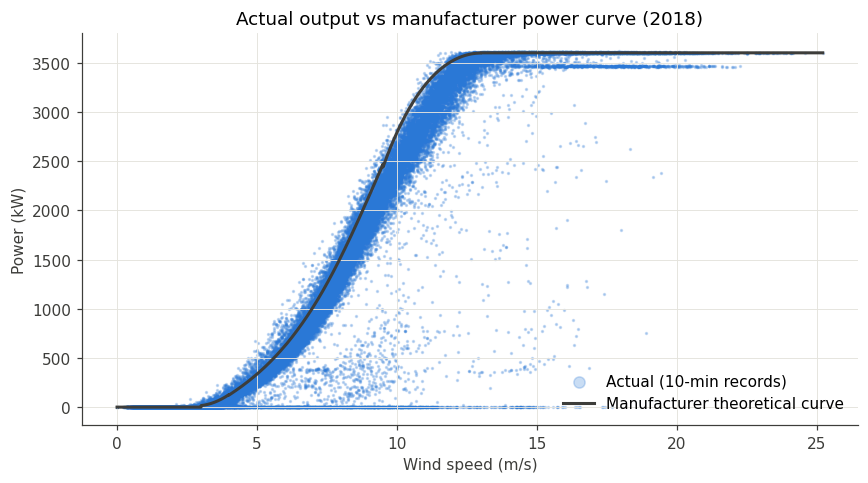

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df.wind_speed, df.power_kw, s=1.5, alpha=0.25, color="#2a78d6", label="Actual (10-min records)", rasterized=True)
curve = df.sort_values("wind_speed")
ax.plot(curve.wind_speed, curve.theo_power_kw, color=INK, lw=2, label="Manufacturer theoretical curve")
ax.set(xlabel="Wind speed (m/s)", ylabel="Power (kW)", title="Actual output vs manufacturer power curve (2018)")
ax.legend(loc="lower right", frameon=False, markerscale=6)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_power_curve_raw.png", dpi=200); plt.show()

Points sitting on zero at high wind, horizontal bands below rated power, and the scatter under the curve are exactly the abnormal states we must **keep** for clustering.

## B. Data preprocessing

##### B1. PARSE AD SORT TIMESTAMPS

In [39]:
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%d %m %Y %H:%M", errors="coerce")
n_bad_ts = int(df["timestamp"].isna().sum())
print("Unparseable timestamps:", n_bad_ts)
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
print("Range:", df.timestamp.min(), "->", df.timestamp.max())
print("Sorted ascending:", df.timestamp.is_monotonic_increasing)

Unparseable timestamps: 0
Range: 2018-01-01 00:00:00 -> 2018-12-31 23:50:00
Sorted ascending: True


##### B2. MISSING VALUES

In [40]:
null_counts = df.isna().sum()
null_counts.to_frame("null_count")

,null_count
timestamp,0
power_kw,0
wind_speed,0
theo_power_kw,0
wind_dir,0


##### B3. DUPLICATES

In [41]:
n_exact_dup = int(df.duplicated().sum())
n_ts_dup = int(df.timestamp.duplicated().sum())
print("Exact duplicates rows:", n_exact_dup, "Timestamp duplicates:", n_ts_dup)

df = df.drop_duplicates()
if df.timestamp.duplicated().any():
    df = df.groupby("timestamp", as_index=False).mean(numeric_only=True)

Exact duplicates rows: 0 Timestamp duplicates: 0


##### B4. MISSING 10 MNUTES INTERVAL (TIME GAPS)


No nulls does **not** mean no missing data: some 10-minute slots are simply absent. We **do not impute** them, because inventing power readings would invent energy and bias the loss estimate. We record the gaps instead, so the loss figures can be reported as *"over recorded intervals"*.

In [42]:
full_grid = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="10min")
n_missing_slots = len(full_grid) - len(df)
print(f"Expected slots: {len(full_grid):,} | recorded: {len(df):,} | missing: {n_missing_slots:,} ({n_missing_slots/len(full_grid):.1%})")

df["gap_before_min"] = df.timestamp.diff().dt.total_seconds().div(60).fillna(10)
gaps = df.loc[df.gap_before_min > 10, ["timestamp", "gap_before_min"]].copy()
gaps["missing_slots"] = (gaps.gap_before_min / 10 - 1).astype(int)
print("\nLargest gaps:")
print(gaps.sort_values("missing_slots", ascending=False).head(5).to_string(index=False))

expected = pd.Series(full_grid.month).value_counts().sort_index()
recorded = df.timestamp.dt.month.value_counts().sort_index()
coverage = pd.DataFrame({"expected": expected, "recorded": recorded})
coverage["coverage_%"] = 100 * coverage.recorded / coverage.expected
coverage

Expected slots: 52,560 | recorded: 50,530 | missing: 2,030 (3.9%)

Largest gaps:
          timestamp  gap_before_min  missing_slots
2018-01-30 14:40:00       6,260.000            625
2018-10-02 16:30:00       5,470.000            546
2018-11-14 12:00:00       5,210.000            520
2018-10-03 06:30:00         740.000             73
2018-10-03 14:10:00         450.000             44


,expected,recorded,coverage_%
1,4464,3817,85.506
2,4032,4032,100.000
3,4464,4463,99.978
4,4320,4305,99.653
5,4464,4449,99.664
6,4320,4245,98.264
7,4464,4464,100.000
8,4464,4425,99.126
9,4320,4000,92.593
10,4464,4083,91.465


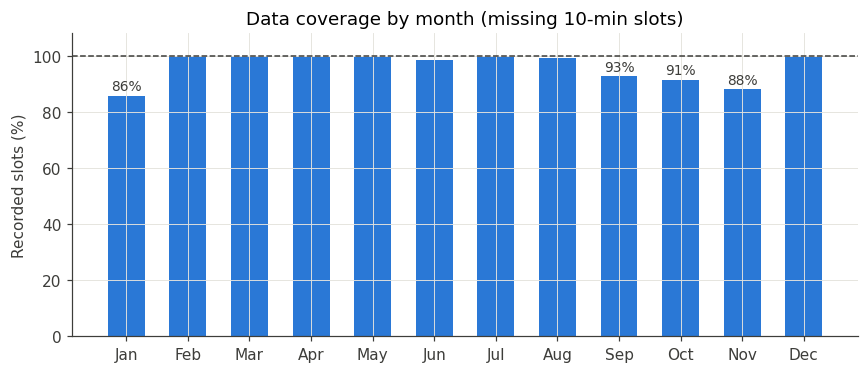

In [43]:
fig, ax = plt.subplots(figsize=(8, 3.5))
months = pd.to_datetime(coverage.index.astype(str), format="%m").strftime("%b")
ax.bar(months, coverage["coverage_%"], color="#2a78d6", width=0.6)
ax.axhline(100, color=INK, lw=1, ls="--")
for x, v in zip(months, coverage["coverage_%"]):
    if v < 95: ax.text(x, v + 1, f"{v:.0f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set(ylim=(0, 108), ylabel="Recorded slots (%)", title="Data coverage by month (missing 10-min slots)")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_coverage_by_month.png", dpi=200); plt.show()

##### B5. Range validation — remove only physically impossible values
| Rule | Why |
|---|---|
| wind speed < 0 or > 40 m/s | negative speed is impossible; > 40 m/s is a sensor fault for this site |
| wind direction outside 0–360° | not a valid bearing |
| power > 110 % of rated | the turbine cannot exceed its rating by this much |
| theoretical power outside 0–rated | the manufacturer curve cannot do this |

Small **negative power** is *not* removed: it is the turbine drawing grid power while idle, which is real information about shutdown states.

In [44]:
RATED_KW = df.theo_power_kw.max()
impossible = (
    (df.wind_speed < 0) | (df.wind_speed > 40) |
    (df.wind_dir < 0) | (df.wind_dir > 360) |
    (df.power_kw > 1.10 * RATED_KW) |
    (df.theo_power_kw < 0) | (df.theo_power_kw > RATED_KW)
)
n_impossible = int(impossible.sum())
print("Rated power (kW):", RATED_KW)
print("Impossible records removed:", n_impossible)
df = df.loc[~impossible].reset_index(drop=True)
df["wind_dir"] = df.wind_dir % 360          # 360° and 0° are the same bearing

n_neg_power = int((df.power_kw < 0).sum())
print(f"Negative-power records kept (idle consumption): {n_neg_power}, min = {df.power_kw.min():.2f} kW")

Rated power (kW): 3600.0
Impossible records removed: 0
Negative-power records kept (idle consumption): 57, min = -2.47 kW


##### B6. Data quality summary (goes straight into the report)

In [45]:
dq = pd.DataFrame([
    ("Raw records", f"{len(raw):,}", "As downloaded"),
    ("Unparseable timestamps", n_bad_ts, "Format DD MM YYYY HH:MM"),
    ("Null values (all columns)", int(null_counts.sum()), "No imputation needed"),
    ("Exact duplicate rows", n_exact_dup, "Dropped if present"),
    ("Duplicate timestamps", n_ts_dup, "Averaged if present"),
    ("Missing 10-min slots", f"{n_missing_slots:,} ({n_missing_slots/len(full_grid):.1%})", "Not imputed; flagged via gap_before_min"),
    ("Largest single gap", f"{gaps.missing_slots.max():,} slots (~{gaps.gap_before_min.max()/60/24:.1f} days)", "Reported as limitation"),
    ("Impossible values removed", n_impossible, "Range rules in B5"),
    ("Negative power records", n_neg_power, "Kept — idle/shutdown signal"),
    ("Final records", f"{len(df):,}", "Used for all later steps"),
], columns=["Check", "Result", "Action"])
dq

,Check,Result,Action
0,Raw records,"50,530",As downloaded
1,Unparseable timestamps,0,Format DD MM YYYY HH:MM
2,Null values (all columns),0,No imputation needed
3,Exact duplicate rows,0,Dropped if present
4,Duplicate timestamps,0,Averaged if present
5,Missing 10-min slots,"2,030 (3.9%)",Not imputed; flagged via gap_before_min
6,Largest single gap,625 slots (~4.3 days),Reported as limitation
7,Impossible values removed,0,Range rules in B5
8,Negative power records,57,Kept — idle/shutdown signal
9,Final records,"50,530",Used for all later steps


## C. Feature engineering

### C1. Cut-in speed and operating region (read from the manufacturer curve)
The proposal says cut-in is read from the first wind speed where theoretical power > 0. In this data that is **≈ 3.0 m/s**. Between 3.0 and 3.5 m/s, however, expected output is only ~16–52 kW, so a reading of 0 kW there is ambiguous (sensor noise, start-up delay) rather than a clear stoppage.

We therefore define the **operating region** as wind speed ≥ cut-in + 0.5 m/s = **3.5 m/s**. This is the threshold the proposal's figures (2,220 zero-output intervals) were based on, and the energy left out is negligible (printed below).

In [46]:
CUT_IN_WS = df.loc[df.theo_power_kw > 0, "wind_speed"].min()
RATED_WS  = df.loc[df.theo_power_kw >= RATED_KW, "wind_speed"].min()
OPERATING_WS = round(CUT_IN_WS + CUTIN_BUFFER, 1)
print(f"Data-derived cut-in: {CUT_IN_WS:.2f} m/s | rated speed: {RATED_WS:.2f} m/s | operating region: >= {OPERATING_WS} m/s")

band = df.wind_speed.between(CUT_IN_WS, OPERATING_WS, inclusive="left")
print(f"Theoretical energy between {CUT_IN_WS:.1f} and {OPERATING_WS} m/s: "
      f"{df.loc[band,'theo_power_kw'].sum()*INTERVAL_H/1000:.1f} MWh "
      f"({df.loc[band,'theo_power_kw'].sum()/df.theo_power_kw.sum():.2%} of the year)")
for thr in (CUT_IN_WS, OPERATING_WS):
    print(f"Zero/negative output with wind >= {thr:.1f} m/s: {((df.wind_speed >= thr) & (df.power_kw <= 0)).sum():,} intervals")
df["in_operating_region"] = df.wind_speed >= OPERATING_WS

Data-derived cut-in: 3.00 m/s | rated speed: 13.00 m/s | operating region: >= 3.5 m/s
Theoretical energy between 3.0 and 3.5 m/s: 10.7 MWh (0.09% of the year)
Zero/negative output with wind >= 3.0 m/s: 3,514 intervals
Zero/negative output with wind >= 3.5 m/s: 2,220 intervals


### C2. Power ratio and residual
- **power_ratio** = actual ÷ theoretical. Scale-free measure of how well the turbine follows its curve (1 = on curve, 0 = stopped). Defined only inside the operating region, because dividing by a near-zero theoretical value explodes. Negative power is clipped to 0 first.
- **residual_kw** = theoretical − actual (kW). Positive = shortfall. Kept signed for clustering.
- **shortfall_kwh** = max(residual, 0) × 1/6 h → the manufacturer-baseline energy loss per record. (The ML-baseline loss is added later from Umair's healthy-curve model.)

In [47]:
power_pos = df.power_kw.clip(lower=0)
df["power_ratio"] = np.where(df.in_operating_region, power_pos / df.theo_power_kw, np.nan)
df["power_ratio"] = df.power_ratio.clip(*RATIO_CLIP)
df["residual_kw"] = df.theo_power_kw - df.power_kw

df["actual_kwh"]    = power_pos * INTERVAL_H
df["theo_kwh"]      = df.theo_power_kw * INTERVAL_H
df["shortfall_kwh"] = df.residual_kw.clip(lower=0) * INTERVAL_H

print(f"Actual energy:      {df.actual_kwh.sum()/1000:,.0f} MWh")
print(f"Theoretical energy: {df.theo_kwh.sum()/1000:,.0f} MWh")
print(f"Shortfall (sum of below-curve intervals): {df.shortfall_kwh.sum()/1000:,.0f} MWh "
      f"= {df.shortfall_kwh.sum()/df.theo_kwh.sum():.1%} of expected")
df[["power_ratio", "residual_kw"]].describe().T

Actual energy:      11,013 MWh
Theoretical energy: 12,567 MWh
Shortfall (sum of below-curve intervals): 1,600 MWh = 12.7% of expected


,count,mean,std,min,25%,50%,75%,max
power_ratio,"40,635.000",0.834,0.259,0.000,0.809,0.893,0.974,1.500
residual_kw,"50,530.000",184.491,427.702,-598.741,0.000,66.683,194.563,"3,600.000"


### C3. Wind direction: sine/cosine components and 30° sectors
Direction is circular — 359° and 1° are 2° apart, but numerically 358 apart. Sine/cosine puts every bearing on a circle so models see the true distance. Sectors (0–30°, 30–60°, …) are for **reporting** loss by direction (yaw misalignment, wake effects).

In [48]:
rad = np.deg2rad(df.wind_dir)
df["wd_sin"] = np.sin(rad)
df["wd_cos"] = np.cos(rad)

sector_start = (df.wind_dir // DIR_SECTOR * DIR_SECTOR).astype(int)
df["dir_sector"] = sector_start.astype(str) + "–" + (sector_start + DIR_SECTOR).astype(str) + "°"
df["dir_sector_start"] = sector_start      # numeric version for sorting / plotting
df.groupby("dir_sector_start").size().rename("records").to_frame().T

dir_sector_start,0,30,60,90,120,150,180,210,240,270,300,330
records,5216,12569,10592,1497,995,1626,7686,3902,2305,1555,1165,1422


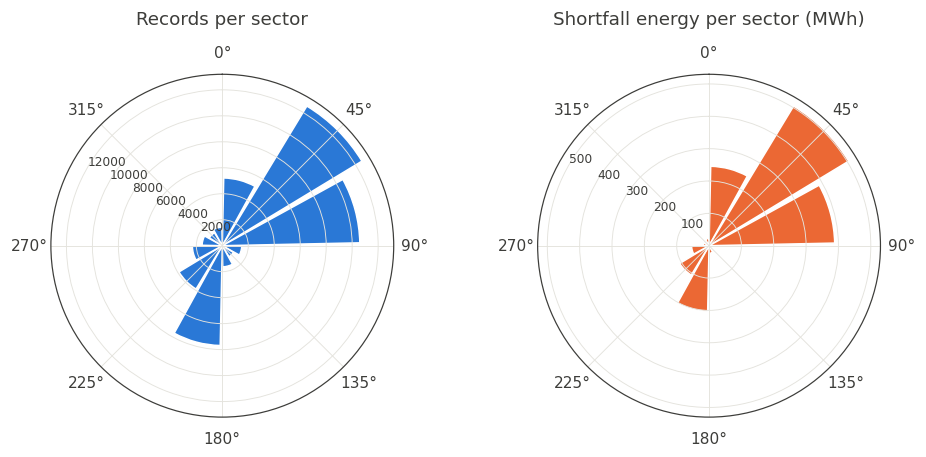

In [49]:
# Wind rose: share of records and of shortfall energy per 30° sector
rose = df.groupby("dir_sector_start").agg(records=("power_kw", "size"), shortfall_mwh=("shortfall_kwh", lambda s: s.sum()/1000))
theta = np.deg2rad(rose.index + DIR_SECTOR / 2)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), subplot_kw={"projection": "polar"})
for ax, col, title, c in [(axes[0], "records", "Records per sector", "#2a78d6"),
                          (axes[1], "shortfall_mwh", "Shortfall energy per sector (MWh)", "#eb6834")]:
    ax.bar(theta, rose[col], width=np.deg2rad(DIR_SECTOR) * 0.92, color=c, edgecolor="white", linewidth=1)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rlabel_position(300)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(title, pad=14, color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_wind_rose.png", dpi=200); plt.show()

### C4. Wind-speed bins (0.5 m/s) and time features for reporting

In [50]:
df["ws_bin"] = (df.wind_speed // WS_BIN * WS_BIN).round(1)    
df["month"] = df.timestamp.dt.month                            
df["month_name"] = df.timestamp.dt.strftime("%b")
df["hour"] = df.timestamp.dt.hour
df[["timestamp", "wind_speed", "ws_bin", "month", "hour"]].head()

,timestamp,wind_speed,ws_bin,month,hour
0,2018-01-01 00:00:00,5.311,5.000,1,0
1,2018-01-01 00:10:00,5.672,5.500,1,0
2,2018-01-01 00:20:00,5.216,5.000,1,0
3,2018-01-01 00:30:00,5.660,5.500,1,0
4,2018-01-01 00:40:00,5.578,5.500,1,0


### C5. Rule-based reference state (NOT a label)
The data has no fault labels. These simple physical rules give Umair a **reference** to check whether each cluster makes physical sense (proposal 4.4, "physical rule check"), and give Safuan a first sanity check on where losses come from. The final operating states still come from clustering.

| rule_state | Condition |
|---|---|
| `below_operating_range` | wind < operating threshold |
| `zero_output` | wind ≥ threshold **and** power ≤ 0 (shutdown-like) |
| `underperforming` | power ratio < 0.80 (includes curtailment-like plateaus) |
| `near_curve` | everything else |

**Known limits of the rules (why clustering is still needed):** the flat band at ~3,450 kW above ~13 m/s is a curtailment-like plateau, but its ratio (~0.96) is above 0.80 so the rules call it `near_curve`. The rules also cannot tell curtailment from degradation inside `underperforming`. Clustering on ratio + residual + wind speed is what separates these.

In [51]:
conds = [
    ~df.in_operating_region,
    df.in_operating_region & (df.power_kw <= 0),
    df.in_operating_region & (df.power_ratio < UNDERPERF_RATIO),
]
df["rule_state"] = np.select(conds, ["below_operating_range", "zero_output", "underperforming"], default="near_curve")

state_tbl = df.groupby("rule_state").agg(
    records=("power_kw", "size"),
    hours=("power_kw", lambda s: len(s) * INTERVAL_H),
    shortfall_mwh=("shortfall_kwh", lambda s: s.sum() / 1000),
)
state_tbl["share_of_shortfall_%"] = 100 * state_tbl.shortfall_mwh / state_tbl.shortfall_mwh.sum()
state_tbl.sort_values("shortfall_mwh", ascending=False)

,records,hours,shortfall_mwh,share_of_shortfall_%
rule_state,,,,
near_curve,31197,"5,199.500",700.226,43.764
zero_output,2220,370.000,456.134,28.508
underperforming,7218,"1,203.000",436.014,27.251
below_operating_range,9895,"1,649.167",7.619,0.476


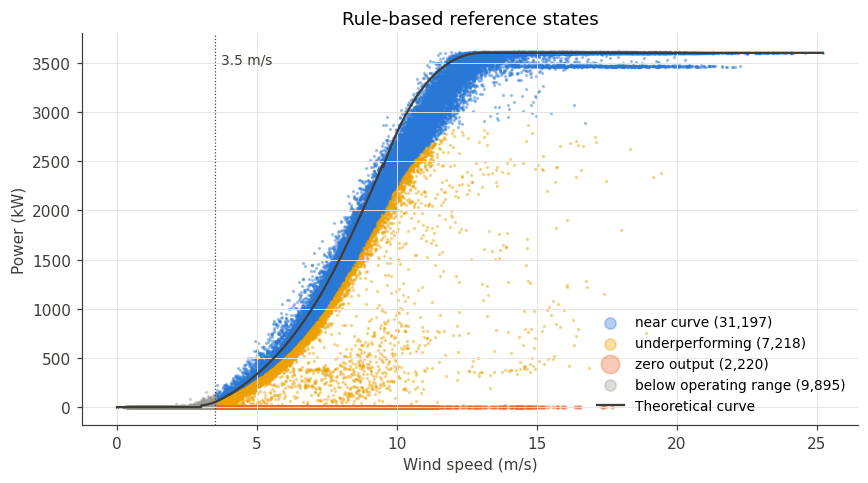

In [52]:
order = ["near_curve", "underperforming", "zero_output", "below_operating_range"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in order:
    d = df[df.rule_state == s]
    ax.scatter(d.wind_speed, d.power_kw, s=4 if s == "zero_output" else 1.5, alpha=0.35, color=COL[s], label=f"{s.replace('_',' ')} ({len(d):,})", rasterized=True)
ax.plot(curve.wind_speed, curve.theo_power_kw, color=INK, lw=1.5, label="Theoretical curve")
ax.axvline(OPERATING_WS, color=INK, lw=0.8, ls=":")
ax.text(OPERATING_WS + 0.2, RATED_KW * 0.97, f"{OPERATING_WS} m/s", fontsize=9, color=INK)
ax.set(xlabel="Wind speed (m/s)", ylabel="Power (kW)", title="Rule-based reference states")
ax.legend(loc="lower right", frameon=False, markerscale=6, fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_rule_states.png", dpi=200); plt.show()

### C6. Feature dictionary (the *final feature table with reasons*)

In [53]:
feat_dict = pd.DataFrame([
    ("wind_speed", "Original", "Main driver of power output", "Clustering + regression input"),
    ("power_kw", "Original", "Actual output — the quantity we judge", "Clustering input; regression TARGET"),
    ("theo_power_kw", "Original", "Manufacturer expectation", "Reference only (never a regression input)"),
    ("wind_dir", "Original", "Bearing the wind comes from", "Replaced by wd_sin / wd_cos in models"),
    ("power_ratio", "Engineered", "Scale-free closeness to curve; separates stop / curtail / normal", "Clustering input"),
    ("residual_kw", "Engineered", "Size of the gap in kW; large at high wind when output is lost", "Clustering input"),
    ("wd_sin, wd_cos", "Engineered", "Circular encoding so 359° ≈ 1°", "Regression input; optional clustering input"),
    ("dir_sector", "Engineered", "30° sectors for loss-by-direction tables", "Reporting only"),
    ("ws_bin", "Engineered", "0.5 m/s bins (IEC power-curve practice)", "Reporting only"),
    ("month, hour", "Engineered", "When losses happen; month = CV block", "Reporting + CV groups only (leakage risk as inputs)"),
    ("in_operating_region", "Engineered flag", f"wind ≥ {OPERATING_WS} m/s", "Selects clustering subset"),
    ("rule_state", "Engineered flag", "Physical-rule reference state", "Cluster sanity check, not a label"),
    ("actual_kwh, theo_kwh, shortfall_kwh", "Engineered", "Energy per 10-min record (kW × 1/6 h)", "Loss quantification (Safuan)"),
    ("gap_before_min", "Engineered flag", "Minutes since previous record", "Documents missing intervals"),
], columns=["feature", "type", "reason", "role"])
feat_dict

,feature,type,reason,role
0,wind_speed,Original,Main driver of power output,Clustering + regression input
1,power_kw,Original,Actual output — the quantity we judge,Clustering input; regression TARGET
2,theo_power_kw,Original,Manufacturer expectation,Reference only (never a regression input)
3,wind_dir,Original,Bearing the wind comes from,Replaced by wd_sin / wd_cos in models
4,power_ratio,Engineered,Scale-free closeness to curve; separates stop ...,Clustering input
5,residual_kw,Engineered,Size of the gap in kW; large at high wind when...,Clustering input
6,"wd_sin, wd_cos",Engineered,Circular encoding so 359° ≈ 1°,Regression input; optional clustering input
7,dir_sector,Engineered,30° sectors for loss-by-direction tables,Reporting only
8,ws_bin,Engineered,0.5 m/s bins (IEC power-curve practice),Reporting only
9,"month, hour",Engineered,When losses happen; month = CV block,Reporting + CV groups only (leakage risk as in...


### D. Model-ready outputs

### D1. Clustering input 
- Subset: operating region only (below it, the turbine is simply waiting for wind — nothing to cluster).
- Features: `wind_speed, power_kw, power_ratio, residual_kw` (+ optional `wd_sin, wd_cos` for the with/without-direction test in the proposal).
- **StandardScaler**: K-Means and DBSCAN use distances, so features in kW (thousands) would otherwise drown out the ratio (0–1.5). Fitting on all data is fine here because clustering has no train/test split.

In [55]:
CLUSTER_FEATS = ["wind_speed", "power_kw", "power_ratio", "residual_kw"]
CLUSTER_FEATS_DIR = CLUSTER_FEATS + ["wd_sin", "wd_cos"]

clus = df.loc[df.in_operating_region].copy()
assert clus[CLUSTER_FEATS_DIR].notna().all().all(), "NaNs in clustering features"

scaler = StandardScaler().fit(clus[CLUSTER_FEATS])
scaled = pd.DataFrame(scaler.transform(clus[CLUSTER_FEATS]), columns=[f"{c}_z" for c in CLUSTER_FEATS], index=clus.index)
# sin/cos already sit in [-1, 1], so they are added unscaled
cluster_input = pd.concat([clus[["timestamp"]], scaled, clus[["wd_sin", "wd_cos"]]], axis=1)
print("Clustering rows:", len(cluster_input))
cluster_input.describe().T[["mean", "std", "min", "max"]]

Clustering rows: 40635


,mean,std,min,max
timestamp,2018-07-04 14:42:50.468807680,NaN,2018-01-01 00:00:00,2018-12-31 23:50:00
wind_speed_z,0.000,1.000,-1.454,4.445
power_kw_z,-0.000,1.000,-1.275,1.563
power_ratio_z,-0.000,1.000,-3.218,2.567
residual_kw_z,-0.000,1.000,-1.774,7.229
wd_sin,0.308,0.626,-1.000,1.000
wd_cos,0.117,0.706,-1.000,1.000


### D2. Regression input 
- **X** = `wind_speed, wd_sin, wd_cos`  ·  **y** = `power_kw`  ·  **groups** = `month`
- Train only on rows Umair's clustering labels as *normal*; until then `rule_state == "near_curve"` is a reasonable stand-in for testing code.
- No scaling needed: Random Forest and XGBoost split on thresholds, so feature scale does not matter.
- Month-blocked CV: `LeaveOneGroupOut` with `groups=month` holds out a whole month per fold, as stated in the proposal.

In [56]:
REG_X, REG_Y, REG_GROUP = ["wind_speed", "wd_sin", "wd_cos"], "power_kw", "month"

demo = df[df.rule_state == "near_curve"]   # placeholder for the clustering 'normal' state
logo = LeaveOneGroupOut()
for i, (tr, te) in enumerate(logo.split(demo[REG_X], demo[REG_Y], groups=demo[REG_GROUP])):
    if i < 3:
        print(f"Fold {i+1}: train {len(tr):,} rows | test month = {demo.iloc[te].month_name.iloc[0]} ({len(te):,} rows)")
print(f"... {logo.get_n_splits(groups=demo[REG_GROUP])} folds in total")

Fold 1: train 29,009 rows | test month = Jan (2,188 rows)
Fold 2: train 28,544 rows | test month = Feb (2,653 rows)
Fold 3: train 27,810 rows | test month = Mar (3,387 rows)
... 12 folds in total


In [57]:
OUT_COLS = ["timestamp", "month", "month_name", "hour", "gap_before_min",
            "wind_speed", "ws_bin", "wind_dir", "wd_sin", "wd_cos", "dir_sector", "dir_sector_start",
            "power_kw", "theo_power_kw", "power_ratio", "residual_kw",
            "actual_kwh", "theo_kwh", "shortfall_kwh", "in_operating_region", "rule_state"]
df[OUT_COLS].to_csv(OUT_DIR / "wind_features.csv", index=False)
cluster_input.to_csv(OUT_DIR / "cluster_input_scaled.csv", index_label="row_id")
joblib.dump({"scaler": scaler, "features": CLUSTER_FEATS}, OUT_DIR / "cluster_scaler.joblib")
dq.to_csv(OUT_DIR / "data_quality_summary.csv", index=False)
feat_dict.to_csv(OUT_DIR / "feature_dictionary.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT_DIR.glob("*.csv")), "cluster_scaler.joblib", sep="\n  ")
print("Figures:", *sorted(p.name for p in FIG_DIR.glob("*.png")), sep="\n  ")

Saved:
  cluster_input_scaled.csv
  data_quality_summary.csv
  feature_dictionary.csv
  wind_features.csv
  cluster_scaler.joblib
Figures:
  01_power_curve_raw.png
  02_coverage_by_month.png
  03_wind_rose.png
  04_rule_states.png


### E. Handover notes
**Umair (modelling)**
- Load `out/01_preprocessing/cluster_input_scaled.csv`; cluster on the `*_z` columns (try with and without `wd_sin, wd_cos`). `row_id` matches the row position in `out/01_preprocessing/wind_features.csv`, so cluster labels can be joined back.
- Only the operating region (wind ≥ 3.5 m/s, 40,635 rows) is in the clustering file. The other 9,895 rows get no cluster label; tag them `below_operating_range` when joining back.
- To read cluster centres in real units: `joblib.load("out/01_preprocessing/cluster_scaler.joblib")["scaler"].inverse_transform(centres)`.
- Use `rule_state` for the physical rule check on clusters (reference only, not a label).
- Regression: X = `wind_speed, wd_sin, wd_cos`, y = `power_kw`, CV = `LeaveOneGroupOut` with `groups=month`. Train on the cluster chosen as *normal* only. Never use `theo_power_kw`, `month` or `hour` as inputs.
- Predict expected power for **all** 50,530 rows so the ML-baseline loss can be computed.

**Safuan (loss & sustainability)**
- `shortfall_kwh` = manufacturer-baseline loss per record. Once Umair predicts expected power, ML-baseline loss = `max(predicted − power_kw, 0) × 1/6`.
- Group by `month_name`, `ws_bin`, `dir_sector` and cluster state for the Pareto chart. CO₂ = MWh × 0.740.
- Losses cover **recorded** intervals only (≈ 3.9 % of slots are missing) — state this as a limitation.

**Ashraf (report)**
- `out/01_preprocessing/data_quality_summary.csv`, `out/01_preprocessing/feature_dictionary.csv` and `figures/` are ready to drop into the Preprocessing & Feature Engineering section.